# ЛР №2. Какие вершины и рёбра графа модели ЛР №1 нужны: матрица Фишера, вынос за три сигмы и расстояние Кульбака–Лейблера

**Вариант 4-4-2.** Тройка методов:

| № | метод из задания | как реализован здесь |
|---|---|---|
| 1.4 | оценка матрицы Фишера для вектора или подвектора параметров | $\theta \sim \mathcal N(\hat\theta, F^{-1})$, подвектор — блок $F^{-1}$; для зависимых строк — информация Годамбе (кластерный «сэндвич»), две функции ошибки: L2 и Хьюбер |
| 2.4 | вынос значений за пределы трёх сигм с учётом условного распределения | вход элемента в окне сдвигается в $\mu + \operatorname{sign}(x-\mu)\,k\sigma$, $k \ge 3$, где $\mu, \sigma$ — условные по входам остальных элементов; доля окон $q$ |
| 3.2 | расстояние Кульбака–Лейблера | замкнутая формула для гауссиан, разложение на сдвиг и форму; порог $\tfrac12\chi^2_1(0.95) = 1.92$ нат |

**Модель ЛР №1 — чужая**: уравнение импульса несжимаемой жидкости из работы Алтая Эйнуллаева
([Chessmatus/navie-stocks-aero](https://github.com/Chessmatus/navie-stocks-aero), коммит `13e4e8f`),

$$\partial_t u = -(\nabla u)\,u - \nabla p/\rho + \nu\,\Delta u,$$

записанное деревом выражения (16 вершин, 15 рёбер). Реальные данные — объёмные поля скорости VIC# в следе модели
ветротурбины (Hillestad et al., 2026), те же кадры, что в ЛР №1. Код ЛР №1 подключён без изменений
(`third_party/navie_stocks_aero`), все обращения к нему собраны в `lab02/legacy.py`.

**Результат.**

* Синтетика А (DNS Навье–Стокса, истина: $\theta_A = \theta_V = 1$, контроля нет): оставлены адвекция и вязкость,
  контрольный элемент $-\alpha u$ удалён. Синтетика Б (DNS с трением $\alpha = 0.01$): оставлены все три,
  $\hat\alpha = 0.0083 ± 0.0015$.
* Эксперимент: остаётся только адвекция, $\theta_A = 0.794 ± 0.013$. Вязкость удаляется: $\theta_V = -4.4 ± 6.4$,
  значение ЛР №1 $\theta_V = 1$ лежит в 0.16σ от нуля — данные его не различают.
  Давление по полю скорости не идентифицируемо, а $\rho$ сливается в кинематическое давление $P = p/\rho$.
* Граф: кандидат из 20 вершин и 19 рёбер (дерево ЛР №1 + кандидат $-\alpha u$)
  сводится к уравнению Эйлера: 9 вершин, 8 рёбер.

**Содержание:** 0 — задание и где что сделано; 1 — модель и граф; 2 — что можно оценить; 3 — метод и обоснование;
4 — вычислительный эксперимент; 5 — синтетические данные; 6 — реальные данные; 7 — решение на графе;
8 — выводы и ограничения; 9 — воспроизводимость; источники.

## 0. Задание и где что сделано

| требование / шаг задания | где |
|---|---|
| синтетические данные с генерацией интервенции | раздел 5: две DNS-синтетики с известной структурой, интервенция 2.4 |
| реальные данные с генерацией интервенции | раздел 6: VIC#, случай 1L, та же интервенция |
| графики в ноутбуке с описанием | под каждым графиком — что на нём и какой вывод |
| код отделён от автора, старый код используется | пакет `lab02/`, код ЛР №1 без изменений в `third_party/`, мост `lab02/legacy.py`; раздел 1 рисует граф кодом ЛР №1 |
| описание вычислительного эксперимента со списком источников | раздел 4, `docs/experiment.md`, источники в конце |
| презентация для устного рассказа | `slides/lab2_presentation.pdf` |
| 1. выбрать уравнение ЛР №1 (желательно чужое) | раздел 1: Навье–Стокс Алтая |
| 2. выбрать способ анализа параметров и интервенции | раздел 3: тройка 1.4 – 2.4 – 3.2 |
| 3. литература, теория, обоснование из трёх частей | раздел 3.1–3.3 (по части на метод) и 3.5 (совместимость) |
| 4. распределения параметров по методу, переменным и функции ошибки | 5.1–5.2, 6.1 |
| 5. расстояние между исходным и интервенционным распределениями | 5.3, 6.2 |
| 6. зависимость расстояния от гиперпараметров интервенции | 5.4, 6.3–6.5 |
| 7. каким узлам и рёбрам соответствуют параметры | разделы 1–2 |
| 8. решение об удалении или сохранении | 5.3, 6.2, 6.9, раздел 7 |

In [1]:
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
from IPython.display import Markdown, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

from lab02 import config, estimation, graph, legacy, plots, report  # noqa: E402
from lab02.experiment import NAMES, Design, decision_tests  # noqa: E402

STARTED = time.time()
plots.apply_style()
R = report.load()
REP = R.reports
show = lambda name: report.render(name, R)  # noqa: E731  (renders and saves figures/<name>.pdf|png)
print("результаты:", ", ".join(f"{n}: {REP[n]['seconds']} с" for n in REP),
      f"| Монте-Карло: {len(R.monte_carlo['realizations'])} реализаций")
print("код ЛР №1:", legacy.upstream_fingerprint()["commit"][:7], "| Python", R.environment["python"],
      "| numpy", R.environment["numpy"])

Matplotlib is building the font cache; this may take a moment.


результаты: syn_a: 58.7 с, syn_b: 31.6 с, real: 24.7 с | Монте-Карло: 16 реализаций
код ЛР №1: 13e4e8f | Python 3.13.9 | numpy 2.5.3


## 1. Модель ЛР №1 и её граф

В ЛР №1 правая часть уравнения импульса записана деревом выражения: листья — поля ($u$, $p$) и параметры ($\rho$, $\nu$),
внутренние вершины — операции (градиент, матрично-векторное умножение, лапласиан, сумма), корень — $\partial_t u$.
Ниже — дерево, нарисованное **функцией из ЛР №1** (`plot_tree`), по её же описанию (`navier_stokes_tree`).

дерево ЛР №1: 16 вершин, 15 рёбер


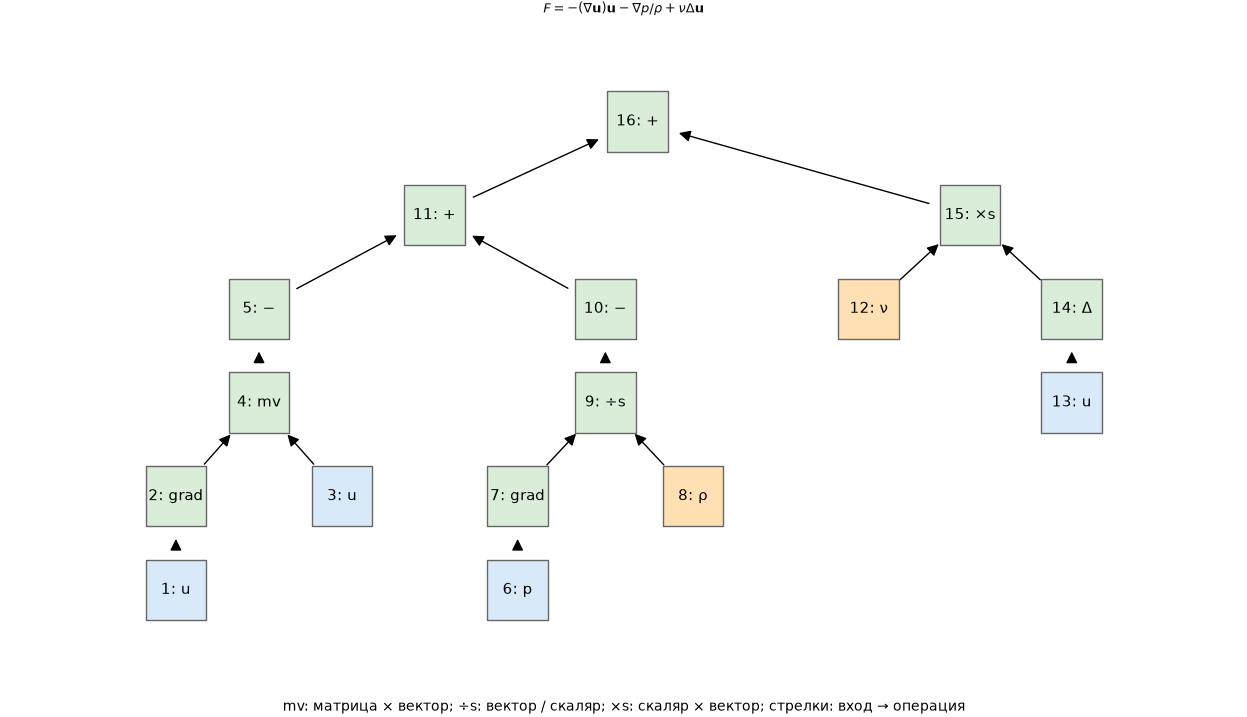

In [2]:
lr1 = legacy.navier_stokes_tree()
fig = legacy.plot_tree(lr1)
order, Z, _ = lr1.matrices()
print(f"дерево ЛР №1: {len(order)} вершин, {int(Z.sum())} рёбер")

**Элементы и параметры.** Решение принимается не о каждом из 15 рёбер по отдельности, а о **ветвях**, которые входят в
итоговую сумму: у каждой ветви свой параметр, и удаление элемента — это гипотеза «параметр равен нулю».
К дереву ЛР №1 добавлен **кандидат** $D = -\alpha u$ (линейное трение), которого в ЛР №1 нет: на синтетике А его быть
не должно, на синтетике Б он есть. Это проверка того, что критерий удаляет лишнее и сохраняет нужное.
Итого кандидатный граф — 20 вершин и 19 рёбер:

$$\partial_t u = \theta_A\,\underbrace{[-(\nabla u)u]}_{A} \;-\; \theta_P\,\underbrace{\nabla p}_{P}
\;+\; \theta_V\,\underbrace{\nu_{ЛР1}\Delta u}_{V} \;+\; \theta_D\,\underbrace{(-u)}_{D},
\qquad \theta_A=\theta_V=1,\ \theta_P = 1/\rho,\ \theta_D = 0 \text{ — модель ЛР №1}.$$

| элемент | вершины | рёбра | параметр |
|---|---|---|---|
| A | n01, n02, n03, n04, n05 | n01→n02, n02→n04, n03→n04, n04→n05, n05→n11 | θ_A, вес ребра n05→n11 (в ЛР1 равен 1) |
| P | n06, n07, n08, n09, n10 | n06→n07, n07→n09, n08→n09, n09→n10, n10→n11 | θ_P = 1/ρ, вес ребра n08→n09 |
| V | n12, n13, n14, n15 | n12→n15, n13→n14, n14→n15, n15→n16 | θ_V = ν/ν_ЛР1, значение вершины n12 |
| D | n17, n18, n19 | n17→n19, n18→n19, n19→n20 | θ_D = α, значение вершины n17 (в ЛР1 нет) |

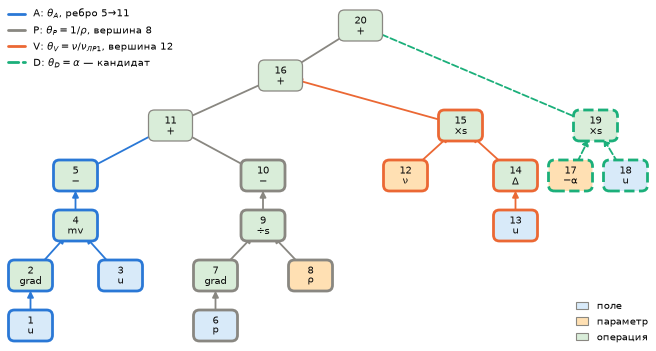

In [3]:
display(Markdown(report.markdown_table(
    ["элемент", "вершины", "рёбра", "параметр"],
    [[r["element"], ", ".join(r["nodes"]), ", ".join(r["edges"]), r["parameter"]] for r in graph.element_table()],
)))
fig = show("tree")

Рамка вершины — цвет элемента, которому она принадлежит (адвекция синяя, давление серое, вязкость оранжевая,
кандидат $D$ — пунктир); заливка — тип вершины. Этот цвет элемента сохраняется во всех графиках ниже.

## 2. Что можно оценить по данным

**Слабая форма.** Производные зашумлённых полей не берутся численно: уравнение умножается на гладкую пробную функцию
с компактным носителем $w$ и интегрируется по окну пространство–время, производные переносятся на $w$
(Messenger & Bortz, 2021). Получается линейная регрессия

$$y = X\theta + r,\qquad y_i = -\!\int u\cdot\partial_t w_i,\quad X_{i,e} = \int (\text{ветвь } e)\cdot w_i ,$$

где строка $i$ — одно окно и одна компонента пробной функции, столбец $e$ — значение ветви $e$ (вход элемента в итоговую
сумму). Пробные функции соленоидальны, $w = \nabla\times(\psi\,e_c)$ с колоколом $\psi = (1-s^2/L^2)^7$, поэтому
$\int \nabla p\cdot w = 0$ **тождественно**: столбец давления нулевой (на синтетике максимум
0). Давление и $\rho$ по полю скорости не идентифицируемы — давление остаётся
множителем Лагранжа условия $\nabla\cdot u = 0$, $\rho$ сливается в $P = p/\rho$.

**Почему подвектор, а не 15 рёбер.** Если дать вес каждому ребру, модель останется линейной по ветвям: производная
выхода по весу ребра — значение ветви, в которой ребро лежит. Матрица Фишера 15 весов
$F_{рёбер} = M F_{ветвей} M^\top$ ($M$ — инцидентность «ребро → ветвь») имеет ранг 2: внутри ветви веса
рёбер неразличимы (корреляция информации ±1), у ветви давления информации нет вовсе. Поэтому оценивается подвектор
$\theta = (\theta_A, \theta_V, \theta_D)$ — по параметру на элемент.

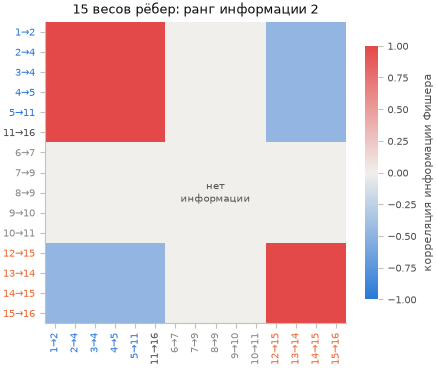

In [4]:
ident = REP["syn_a"]["identifiability"]
assert ident["rank"] == 2 and REP["syn_a"]["meta"]["pressure_column_max"] == 0.0
fig = show("identifiability")

Красные блоки — рёбра одной ветви: корреляция их информации +1, данные видят только сумму их вкладов. Синие — между
ветвями $A$ и $V$ (-0.47). Серый крест — рёбра ветви давления: информации нет (строки занулены, а не нормированы,
чтобы округление не выглядело корреляцией). Ранг 2 — по одному направлению на ветвь $A$ и $V$.

## 3. Метод и обоснование

Обоснование в задании состоит из трёх частей — по одной на метод тройки; ниже каждая часть отвечает на вопросы
«что это», «почему подходит к задаче», «на что опирается». Раздел 3.4 — правило решения, 3.5 — почему методы совместимы.

### 3.1. Распределение параметров: матрица Фишера вектора и подвектора (1.4)

**Что.** Для модели, линейной по $\theta$, с функцией ошибки $S(\theta)$ распределение параметров в приближении
Лапласа — $\mathcal N(\hat\theta, F^{-1})$, где $F$ — информация Фишера (MacKay, 1992; Кузнецов, Токмакова, Стрижов, 2016).
Распределение подвектора — соответствующий блок $F^{-1}$, т.е. обратное дополнение Шура: информация о $\theta_e$
за вычетом той, что объясняется остальными параметрами.

* L2, независимые строки: $F = X^\top X/\sigma^2$.
* **Зависимые строки** (окна перекрываются, соседние окна видят одни и те же вихри): информация Годамбе
  $G = H J^{-1} H$, $H = X^\top \operatorname{diag}(\psi')X$, $J$ — ковариация градиента $S$, суммированного по кластерам
  соседних окон (Godambe, 1960; Liang & Zeger, 1986). Для независимых строк и L2 она совпадает с $F$.
* Функция ошибки Хьюбера ($c = 1.345$, Huber, 1964): квадратичная около нуля, линейная в хвостах;
  $F^{-1} = \mathbb E[\psi^2]/\mathbb E[\psi']^2\,(X^\top X)^{-1}$.

**Почему подходит.** Модель линейна по параметрам элементов, поэтому гауссово приближение точное в пределе большого
числа окон (их 4802 на эксперименте), а распределение получается в замкнутой форме — без сэмплирования
и его шума. Подвектор нужен по разделу 2: идентифицируемы только параметры ветвей.

**Проверки.** Форма — кластерный бутстрэп (1000 повторов). Ширина — 16 независимых реализаций DNS: если $\sigma$ метода
верна, то $\sigma$ совпадает с разбросом оценок между реализациями.

### 3.2. Интервенция: вынос за три сигмы с учётом условного распределения (2.4)

**Над какой переменной.** Наблюдаемая переменная элемента $e$ — его вход $x_e$ в каждом окне (столбец $X_{\cdot e}$).
Условное распределение входа при входах остальных элементов моделируется линейно-гауссовым, отдельно для каждой
компоненты пробной функции:
$$x_e \mid x_{-e} \sim \mathcal N(\mu, \sigma_c^2),\qquad \mu = b_0 + \textstyle\sum_{j\ne e} b_j x_j .$$

**Интервенция.** В доле $q$ окон (все три компоненты окна) вход выносится наружу на своей стороне:
$$x_e' = \mu + \operatorname{sign}(x_e - \mu)\,k\,\sigma_c,\qquad k \ge 3 .$$
Для любого унимодального закона в полосе $\pm 3\sigma$ лежит не меньше $1 - 4/81 \approx 95\,\%$ массы
(правило трёх сигм Пукельсхайма, 1994), так что вынесенные значения — выбросы условного распределения, но не произвольные:
они лежат на линии условного среднего.

**Почему условное.** По теореме Фриша–Во–Ловелла $\theta_e$ определяется только остатком $x_e - \mu$ — частью входа,
не объяснимой другими элементами. Условный вынос разрушает именно её и сохраняет общую с другими входами часть,
поэтому отклик показывает, сколько информации о $\theta_e$ было у данных.

**Сколько информации теряется (теория).** МНК по остатку: невынесенные окна сохраняют наклон $\theta_e$ с весом
$(1-q)\sigma^2$, вынесенное окно даёт ковариацию с откликом $\theta_e k\sigma\,\mathbb E|r| = \theta_e k \sigma^2\sqrt{2/\pi}$.
Отсюда доля потерянного параметра
$$\rho(k,q) = 1 - \frac{1 - q + qk\sqrt{2/\pi}}{1 - q + qk^2},\qquad \theta_e' \approx (1-\rho)\,\theta_e .$$
При $k = 10$, $q = 1$ теряется $\rho = 0.920$ параметра. Вес вынесенного окна растёт как $k^2$, поэтому
выбросы действуют сильнее, чем «правдоподобная» перерисовка из условного закона (плацебо, Candès et al., 2018),
у которой $\rho = q$.

**Гиперпараметры** — $k$ (насколько далеко) и $q$ (какая доля окон); расстояние строится в зависимости от обоих.
**Вариант на уровне сетки:** значения листа дерева ($u$ в вершинах 1, 3, 13) выносятся за $3\sigma$ условного закона по
шести соседям (гауссово марковское поле, Rue & Held, 2005) — раздел 6.7.

Пример на эксперименте: вход адвекции, $k = 10$, $q = 5\,\%$ — вынесено 241 из 4802 окон
(показана одна компонента пробной функции).

вынесено окон: 241 из 4802; |z| вынесенных = 10


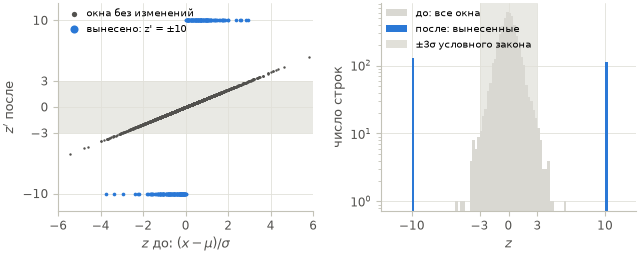

In [5]:
example = report.intervention_example(R)
fig = show("intervention")
z = (example["x_after"] - example["mu"]) / example["sigma"]
assert np.allclose(np.abs(z[example["moved"]]), example["k"])  # every moved value sits exactly at k sigma
print(f"вынесено окон: {example['moved_windows']} из {example['windows']}; |z| вынесенных = {example['k']:g}")

Слева — вход адвекции против своего условного среднего: серые точки — окна без изменений (они лежат в полосе
$\mu \pm 3\sigma$, серые линии), синие — вынесенные на линии $\mu \pm 10\sigma$. Справа — стандартизованные отклонения:
до интервенции почти нормальное распределение внутри $\pm 3\sigma$, после — отдельные пики при $|z| = 10$.

### 3.3. Расстояние Кульбака–Лейблера (3.2)

**Что.** Для $P = \mathcal N(m_P, \Sigma_P)$ (до интервенции) и $Q = \mathcal N(m_Q, \Sigma_Q)$ (после) в размерности $d$
(Kullback & Leibler, 1951)
$$\mathrm{KL}(Q\,\|\,P) = \underbrace{\tfrac12 (m_Q-m_P)^\top \Sigma_P^{-1} (m_Q-m_P)}_{\text{сдвиг}}
+ \underbrace{\tfrac12\big[\operatorname{tr}(\Sigma_P^{-1}\Sigma_Q) - d - \ln\det(\Sigma_P^{-1}\Sigma_Q)\big]}_{\text{форма}} .$$
Сдвиг меряется в единицах ширины исходного распределения: это квадрат сдвига центра «в сигмах», делённый на два.

**Почему подходит.** (1) Для гауссиан KL считается точно, без гистограмм и оценки плотности. (2) Для близких
распределений $\mathrm{KL} \approx \tfrac12\,\delta^\top F \delta$: матрица Фишера — метрика KL (Amari, 2016), так что
расстояние измеряется в той же геометрии, в которой оценено распределение. (3) Порог имеет смысл:
$\tfrac12\chi^2_1(0.95) = 1.92$ нат — сдвиг центра на $1.96\sigma$, уровень 5 %.

**Почему только сдвиг.** Вынос меняет дисперсию входа в $k^2$ раз, поэтому распределение **любого** параметра — и
существующего, и отсутствующего — сужается, и часть «форма» растёт одинаково (на эксперименте у удаляемых $V$ и $D$ она
2.09 и 2.13 нат — выше порога; раздел 6.4). Наличие элемента различает только сдвиг центра.

**Связь с удалением элемента.** Сдвиговая часть после полного разрушения информации о $\theta_e$ равна
$$S_e = \frac{\hat\theta_e^2}{2\sigma_e^2} = \min_{\theta:\,\theta_e = 0} \mathrm{KL}\big(\mathcal N(\hat\theta,\Sigma)\,\big\|\,\mathcal N(\theta,\Sigma)\big),$$
KL до ближайшей модели без элемента (шаг Optimal Brain Surgeon, Hassibi & Stork, 1993; половина квадрата статистики
Вальда). Для интервенции силы $(k,q)$: $\mathrm{KL}_{сдв} \approx \rho(k,q)^2 S_e$.

### 3.4. Правило решения

Для каждого элемента $e$: вход $e$ выносится за $k = 10$ сигм во **всех** окнах ($q = 1$), распределение
пересчитывается, и
$$\text{оставить } e \iff \mathrm{KL}_{сдв}(Q_e\,\|\,P_e) > 1.92\ \text{нат}\quad\text{и}\quad \operatorname{sign}\hat\theta_e \text{ допустим} .$$
Допустимые знаки — физические: перенос с коэффициентом $\theta_A > 0$, вязкость $\nu > 0$ (диссипация), трение $\alpha > 0$
(сток энергии). Из теории выше правило эквивалентно $|\hat\theta_e/\sigma_e| > 1.96/\rho = 2.13$ — тест Вальда,
в котором интервенция задаёт, какую долю информации разрушить. Удаление — **по одному элементу**: из не прошедших правило
удаляется слабейший (наименьший сдвиг), модель переоценивается, проверка повторяется (обратное исключение), потому что
удаление одного коррелированного входа меняет распределение остальных (раздел 6.6). Основная оценка — L2 с информацией
Годамбе; решения по четырём вариантам (L2/Хьюбер × Фишер/Годамбе) сравниваются как проверка устойчивости.

### 3.5. Почему тройка совместима

* **Одна геометрия.** Метод 1.4 задаёт распределение и метрику $F$; интервенция 2.4 сдвигает распределение;
  KL 3.2 — квадратичная форма этого сдвига в метрике $F$. Все три — в гауссовой модели с замкнутыми формулами,
  поэтому расстояние не содержит шума сэмплирования.
* **Одни масштабы.** Условная $\sigma_c$ интервенции — та же величина, что остаточная дисперсия входа в блоке $F^{-1}$
  для подвектора (Фриш–Во–Ловелл): интервенция бьёт ровно по той информации, из которой оценён параметр.
* **Подходят задаче.** Элементы графа — линейные по параметрам ветви, решение — гипотеза $\theta_e = 0$; KL сдвига
  с порогом $\tfrac12\chi^2_1$ — критерий этой гипотезы, а интервенция показывает, при какой доле испорченных окон $q^*$
  элемент становится «видим».
* **Чего тройка не делает.** Распределение гауссово по построению; если остатки зависимы, наивная матрица Фишера
  занижает ширину — поэтому основная оценка Годамбе, и её ширина проверена на независимых реализациях (раздел 5.5).

## 4. Вычислительный эксперимент

| | синтетика А | синтетика Б | эксперимент VIC# |
|---|---|---|---|
| данные | DNS Навье–Стокса, $48^3$, периодический куб, снос $U = 3$ | та же DNS + трение $-\alpha u$, $\alpha = 0.01$ | след модели ветротурбины, случай 1L, 500 Гц, 86 кадров |
| шум | 5 % от пульсаций | 5 % | измерительный |
| истина | $\theta_A = \theta_V = 1$, $\theta_D = 0$ | $\theta_A = \theta_V = 1$, $\theta_D = 0.01$ | неизвестна |
| пробные окна | $m_x = 8$, $m_t = 8$ | $m_x = 8$, $m_t = 8$ | $m_x = 6$, $m_t = 10$ |
| строк / окон / кластеров | 31944 / 10648 / 108 | 31944 / 10648 / 108 | 14406 / 4802 / 144 |

**План.** Сетка по $k$: 3, 4, 5, 7, 10, 15, 20, 30 при $q = 0.05$; сетка по $q$ от
0.0001 до 1 (13 точек) при $k = 10$; по 10 сидов на точку (выбор окон),
столько же для плацебо; решение — в точке $k = 10$, $q = 1$. После каждой интервенции пересчитываются все четыре
распределения (L2/Хьюбер × Фишер/Годамбе). Проверка ширины — 16 независимых реализаций DNS (свой случайный старт и шум).
Все случайные потоки выводятся из одного зерна `Plan.seed` через `SeedSequence`, так что каждая точка воспроизводима отдельно.
Полное описание — `docs/experiment.md`.

syn_a: поле [73, 3, 48, 48, 48] (кадры, компоненты, x, y, z), шаг сетки 0.1309, кадр 0.0156, rms пульсаций 0.58
syn_b: поле [73, 3, 48, 48, 48] (кадры, компоненты, x, y, z), шаг сетки 0.1309, кадр 0.0156, rms пульсаций 0.574
real: поле [86, 3, 53, 33, 33] (кадры, компоненты, x, y, z), шаг сетки 0.001601, кадр 0.002, rms пульсаций 0.0705


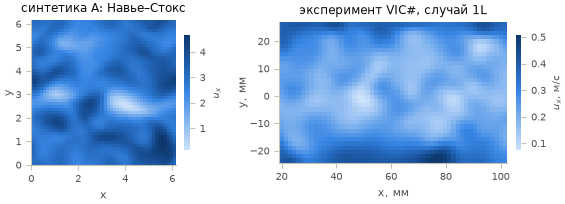

In [6]:
fig = show("snapshots")
for n in REP:
    f = REP[n]["field"]
    print(f"{n}: поле {f['shape']} (кадры, компоненты, x, y, z), шаг сетки {f['h']:.4g}, "
          f"кадр {f['dt']:.3g}, rms пульсаций {f['fluctuation_rms']:.3g}")

Срез продольной скорости $u_x$ в среднем сечении по $z$, первый кадр. Синтетика — изотропная турбулентность
со сносом; эксперимент — след за ротором (дефицит скорости в центре блока).

## 5. Синтетические данные: структура известна

### 5.1. Распределения параметров по методам

Три оценки распределения каждого параметра: информация Годамбе (основная, сплошная линия), наивная матрица Фишера
(строки независимы, пунктир), кластерный бутстрэп (гистограмма).

| данные | параметр | истина | L2, Годамбе: θ ± σ | σ Фишер / σ Годамбе | σ бутстрэп / σ Годамбе | Хьюбер, Годамбе: θ ± σ |
|---|---|---|---|---|---|---|
| синтетика А | $\theta_A$ | 1.0 | 1.00001 ± 0.00018 | 0.48 | 1.00 | 1.00001 ± 0.00016 |
| синтетика А | $\theta_V$ | 1.0 | 1.0032 ± 0.0031 | 0.46 | 0.97 | 1.0026 ± 0.0028 |
| синтетика А | $\theta_D$ | 0.0 | -0.0017 ± 0.0015 | 0.53 | 1.03 | -0.0016 ± 0.0014 |
| синтетика Б | $\theta_A$ | 1.0 | 1.00000 ± 0.00018 | 0.47 | 1.02 | 1.00001 ± 0.00016 |
| синтетика Б | $\theta_V$ | 1.0 | 1.0031 ± 0.0031 | 0.46 | 0.99 | 1.0025 ± 0.0028 |
| синтетика Б | $\theta_D$ | 0.01 | 0.0083 ± 0.0015 | 0.53 | 1.03 | 0.0084 ± 0.0014 |
| эксперимент | $\theta_A$ | — | 0.794 ± 0.013 | 0.61 | 1.01 | 0.808 ± 0.012 |
| эксперимент | $\theta_V$ | — | -4.4 ± 6.4 | 0.58 | 0.99 | -1.6 ± 5.5 |
| эксперимент | $\theta_D$ | — | -0.19 ± 0.90 | 0.57 | 1.00 | -0.31 ± 0.79 |

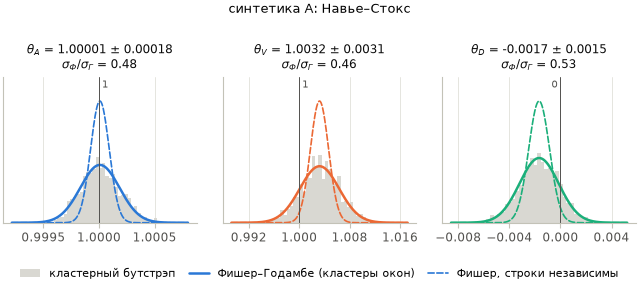

In [7]:
fig = show("methods_syn_a")
display(Markdown(report.table_distributions(R)))

Бутстрэп совпадает с Годамбе по форме и ширине (отношение σ ≈ 1 в таблице), наивный Фишер в
1.9–2.2 раза уже: перекрывающиеся окна не независимы. Оценки несмещены: $\theta_A = 1.00001 ± 0.00018$, $\theta_V = 1.0032 ± 0.0031$,
$\theta_D = -0.0017 ± 0.0015$ при истине 1, 1, 0.

### 5.2. Функции ошибки

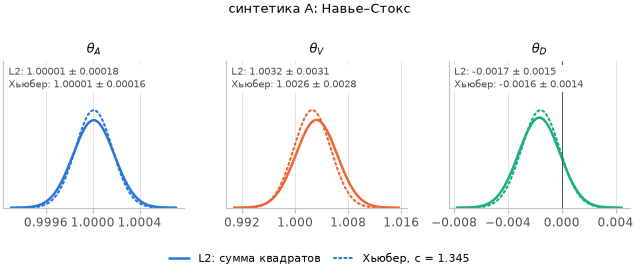

In [8]:
fig = show("losses_syn_a")

На синтетике шум гауссов, и Хьюбер совпадает с L2 по центру; ширина у Хьюбера чуть меньше за счёт хвостов
пульсаций. Решения от выбора функции ошибки не зависят (столбец «4 оценки согласны» ниже).

### 5.3. Расстояние между исходным и интервенционным распределениями и решение

$P$ — распределение до интервенции, $Q$ — после выноса входа элемента за $10\sigma$ во всех окнах.

**синтетика А: Навье–Стокс**

| элемент | P: θ ± σ | Q: θ ± σ | KL сдвиг | KL форма | $S_e$ | решение | 4 оценки согласны |
|---|---|---|---|---|---|---|---|
| адвекция A | 1.00001 ± 0.00018 | 0.0756 ± 0.0025 | 1.38e+07 | 99.3 | 1.62e+07 | **оставить** | да |
| вязкость V | 1.0032 ± 0.0031 | 0.0784 ± 0.0017 | 4.43e+04 | 0.235 | 5.22e+04 | **оставить** | да |
| контроль D (−αu) | -0.0017 ± 0.0015 | -0.00010 ± 0.00017 | 0.523 | 1.72 | 0.594 | удалить ($KL_{сдв} \le 1.92$) | да |

**синтетика Б: + трение α**

| элемент | P: θ ± σ | Q: θ ± σ | KL сдвиг | KL форма | $S_e$ | решение | 4 оценки согласны |
|---|---|---|---|---|---|---|---|
| адвекция A | 1.00000 ± 0.00018 | 0.0756 ± 0.0025 | 1.38e+07 | 100 | 1.61e+07 | **оставить** | да |
| вязкость V | 1.0031 ± 0.0031 | 0.0783 ± 0.0018 | 4.4e+04 | 0.23 | 5.18e+04 | **оставить** | да |
| контроль D (−αu) | 0.0083 ± 0.0015 | 0.00067 ± 0.00016 | 12.5 | 1.74 | 14.8 | **оставить** | да |

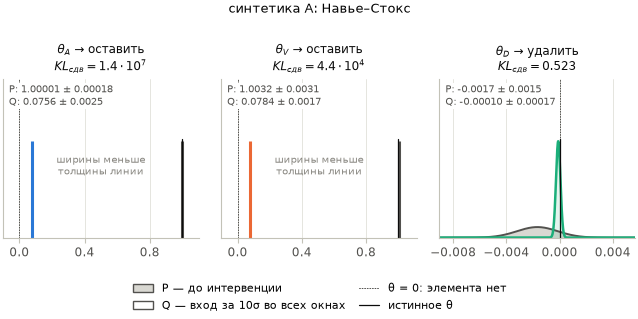

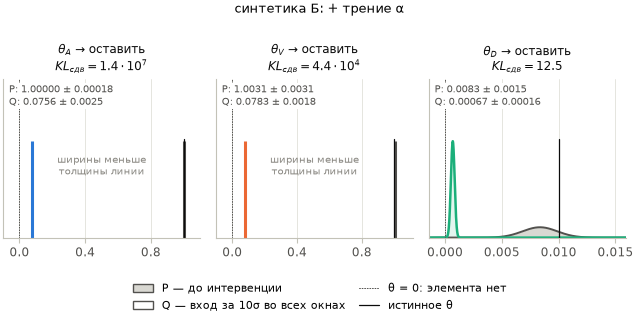

In [9]:
for n in ("syn_a", "syn_b"):
    fig = show(f"pq_{n}")
    display(Markdown(f"**{report.TITLE[n]}**\n\n" + report.table_decisions(REP[n])))
assert REP["syn_a"]["keep"] == {"A": True, "V": True, "D": False}
assert REP["syn_b"]["keep"] == {"A": True, "V": True, "D": True}

* **Существующие элементы теряют параметр**: центр $Q$ уходит к нулю, $\theta' \approx (1-\rho)\theta$ с $\rho = 0.920$;
  сдвиг огромен ($\mathrm{KL}_{сдв} = 1.38e+07$ для $A$), потому что параметр оценён с относительной
  точностью $10^{-4}$.
* **Отсутствующий элемент** (контроль на синтетике А) теряет только шум: $\mathrm{KL}_{сдв} = 0.523$
  < 1.92 → удалить. Тот же элемент на синтетике Б (трение есть) даёт $\mathrm{KL}_{сдв} = 12.5$
  → оставить, при $\hat\alpha = 0.0083 ± 0.0015$ (истина 0.01).
* Теория $\mathrm{KL}_{сдв} = \rho^2 S_e$: для $A$ на синтетике А $\rho^2 S_A = 1.37e+07$
  против измеренных 1.38e+07.

### 5.4. Расстояние в зависимости от гиперпараметров $k$ и $q$

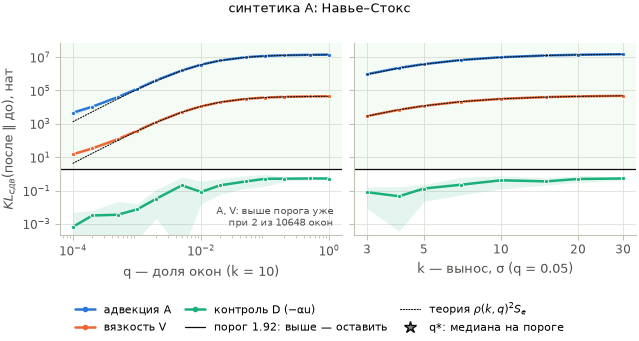

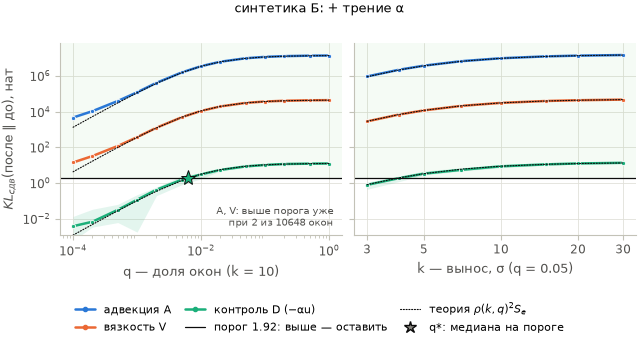

In [10]:
for n in ("syn_a", "syn_b"):
    fig = show(f"kl_{n}")

Медиана по 10 сидам (точки), размах (заливка), теория $\rho(k,q)^2 S_e$ (чёрный пунктир) — для элементов,
которые есть. Выше порога (зелёная зона) — «оставить».

* У $A$ и $V$ сдвиг выше порога уже при 2 вынесенных окнах из 10648 ($q = 10^{-4}$):
  они видны в данных с огромным запасом. Теория совпадает с измерением, начиная с $q \approx 10^{-3}$; при единицах
  окон отклик зависит от того, какие окна попали в выборку.
* Контроль $D$ на синтетике А не пересекает порог ни при каком $k$ и $q$ — его отклик — шум. На синтетике Б он
  пересекает порог при $q^* = 0.00615$ (звезда): слабый, но реальный элемент
  становится виден, когда испорчено ~0.6 % окон.
* По $k$ кривые выходят на насыщение: от $k = 10$ до $30$ сдвиг растёт лишь в 1.5 раза
  ($\rho$ от 0.77 до 0.95 при $q = 0.05$), так что $k = 10$ — уже почти полный вынос.

### 5.5. Проверка ширины распределения на 16 независимых реализациях

| параметр | среднее θ̂ | разброс θ̂ (сд) | Фишер: σ/разброс / покрытие | Годамбе | бутстрэп |
|---|---|---|---|---|---|
| $\theta_A$ | 1.00002 | 3.56e-04 | 0.24 / 0.38 | 0.53 / 0.69 | 0.54 / 0.69 |
| $\theta_V$ | 0.99977 | 3.18e-03 | 0.45 / 0.75 | 0.91 / 0.88 | 0.91 / 0.88 |
| $\theta_D$ | 0.00023 | 1.71e-03 | 0.49 / 0.56 | 0.96 / 0.94 | 0.97 / 0.94 |

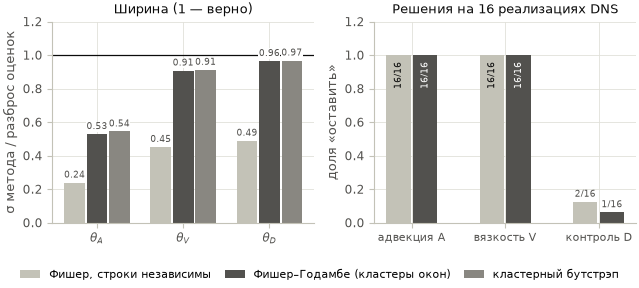

In [11]:
fig = show("monte_carlo")
display(Markdown(report.table_monte_carlo(R.monte_carlo)))

Ширина метода, делённая на настоящий разброс оценок между реализациями (1 — верно), и доля покрытия истины интервалом
$\pm 1.96\sigma$ (номинал 0.95):

* Наивный Фишер занижает ширину в 2–4 раза (отношение 0.24 / 0.45 / 0.49) и
  поэтому чаще ошибочно оставляет отсутствующий контроль: 2/16 реализаций против
  1/16 у Годамбе. Это согласуется с теорией: при верной ширине ложное «оставить»
  (сдвиг выше порога и положительный знак) случается с вероятностью $P(z > 2.13) = 1.7%$, а с шириной,
  заниженной в 2.0 раза, порог фактически $z > 1.04$ и вероятность 15%
  — 2.4 из 16 ожидаемых.
* Годамбе и бутстрэп верны для $V$ и $D$ (0.91, 0.96), но для $A$ всё ещё занижают
  ширину вдвое (0.53). Вероятная причина — часть ошибки $\theta_A$ общая для всей реализации (крупные вихри
  куба, ошибка дискретизации слабой формы): кластеры соседних окон её не видят. На решения это не влияет — $S_A \sim 10^7$, —
  но $\sigma_A$ следует читать как нижнюю границу.
* Решения по $A$ и $V$ — «оставить» во всех 16 реализациях.

## 6. Реальные данные: эксперимент VIC#

### 6.1. Распределения параметров по методам и функциям ошибки

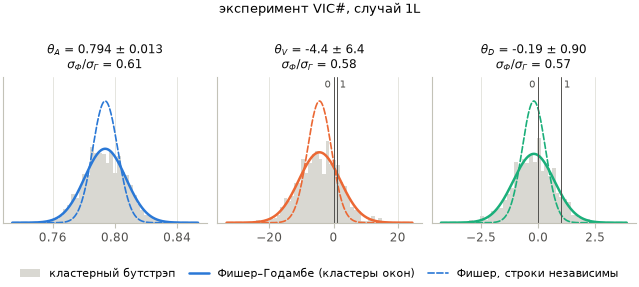

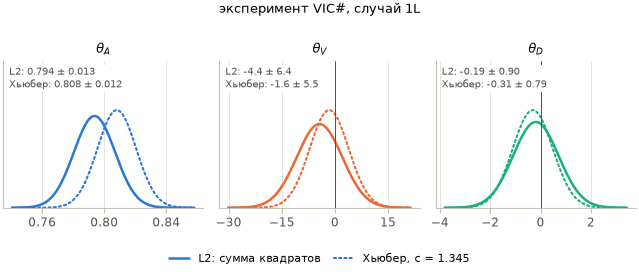

In [12]:
fig = show("methods_real")
fig = show("losses_real")

* $\theta_A = 0.794 ± 0.013$: адвекция видна уверенно, но коэффициент меньше 1 на
  16σ. Это ожидаемо для зашумлённого входа: столбец адвекции вычислен из
  измеренной (сглаженной реконструкцией VIC#) скорости, и ошибка во входе смещает коэффициент к нулю
  (regression dilution); на окнах другого размера $\theta_A$ меняется от 0.72 до 0.85 (раздел 6.8).
* $\theta_V = -4.4 ± 6.4$ и $\theta_D = -0.19 ± 0.90$ — оба совместимы с нулём. Значение ЛР №1 $\theta_V = 1$
  отстоит от нуля на 0.16σ: вязкость при разрешении 1.6 мм данных не видна. В самой ЛР №1 подгонка
  $\nu$ упёрлась в границу поиска ($\nu = 1.8e-06$ м²/с, вдвое больше опорной) и уменьшила невязку лишь на
  0.04% — то же наблюдение, полученное другим методом.
* Наивный Фишер уже Годамбе в 1.6–1.8 раза; бутстрэп с Годамбе совпадает. Хьюбер сдвигает $\theta_A$ на 1σ
  (0.808 ± 0.012) — у остатков тяжёлые хвосты, — но решения те же.
* $R^2 = 0.40$: модель объясняет 40 % дисперсии слабой производной по времени — остальное шум
  измерения и неразрешённые масштабы.

### 6.2. Расстояние между исходным и интервенционным распределениями и решение

| элемент | P: θ ± σ | Q: θ ± σ | KL сдвиг | KL форма | $S_e$ | решение | 4 оценки согласны |
|---|---|---|---|---|---|---|---|
| адвекция A | 0.794 ± 0.013 | 0.0574 ± 0.0020 | 1.54e+03 | 1.41 | 1.79e+03 | **оставить** | да |
| вязкость V | -4.4 ± 6.4 | 0.03 ± 0.49 | 0.234 | 2.09 | 0.23 | удалить ($KL_{сдв} \le 1.92$) | да |
| контроль D (−αu) | -0.19 ± 0.90 | -0.018 ± 0.066 | 0.0177 | 2.13 | 0.0216 | удалить ($KL_{сдв} \le 1.92$) | да |

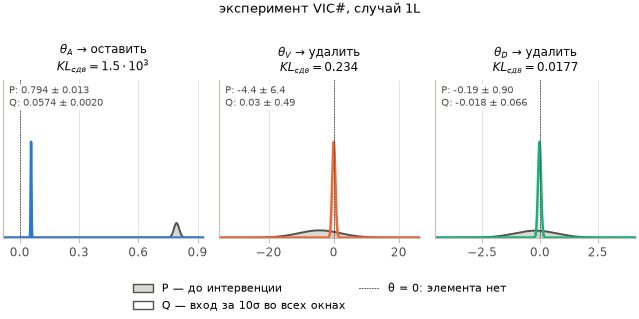

In [13]:
fig = show("pq_real")
display(Markdown(report.table_decisions(REP["real"])))
assert REP["real"]["keep"] == {"A": True, "V": False, "D": False}
assert all(t["unanimous"] for t in REP["real"]["steps"][0]["tests"].values())

Адвекция: $\mathrm{KL}_{сдв} = 1.54e+03$ — оставить. Вязкость и контроль: 0.234 и
0.0177 нат — центр $Q$ уходит к нулю, но он и был в пределах $1\sigma$ от нуля, так что сдвиг
меньше порога — удалить. Все четыре оценки (L2/Хьюбер × Фишер/Годамбе) согласны. Для отсутствующих элементов $Q$ сильно
уже $P$ — это и есть часть «форма», которая в решение не входит.

### 6.3. Расстояние в зависимости от $k$ и $q$

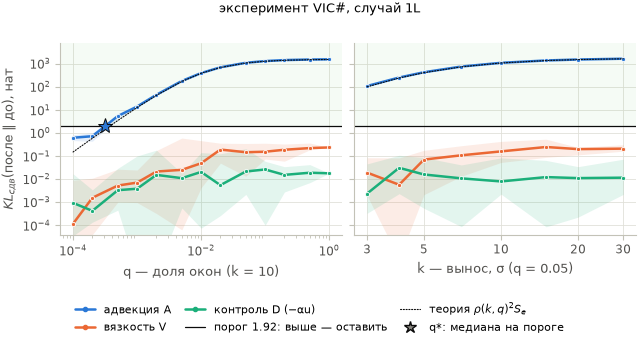

In [14]:
fig = show("kl_real")

$A$ пересекает порог при $q^* = 3.1e-04$ — достаточно испортить ~2 окна из
4802. $V$ и $D$ остаются ниже порога при любых $k$ и $q$: их сдвиг — шум, и он не растёт с силой
интервенции. Теория $\rho^2 S_A$ совпадает с измерением, начиная с $q \approx 5\cdot10^{-4}$; при одном-двух вынесенных окнах
отклик зависит от того, какие именно окна попали в выборку.

### 6.4. Сдвиг и форма: почему в правиле только сдвиг

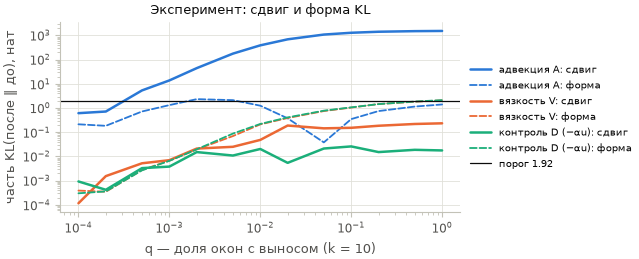

In [15]:
fig = show("kl_parts_real")

Сплошные — сдвиг, штриховые — форма. Форма у $V$ и $D$ растёт с $q$ так же, как у существующей $A$, и при полной силе
превышает порог (2.09 и 2.13 нат). Правило по полному KL оставило бы всё — оно
реагирует на сам факт интервенции, а не на элемент. Сдвиг разделяет $A$ и $V$ на 3.8 порядка.

### 6.5. Чувствительность: функция ошибки и вид интервенции

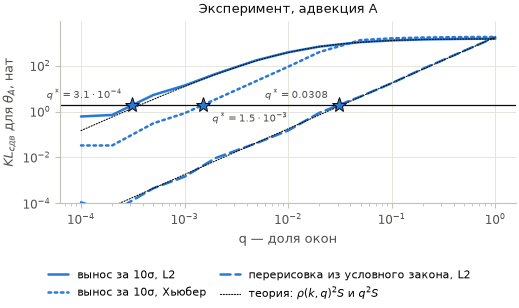

In [16]:
fig = show("q_sensitivity_real")

* **Хьюбер** (точки) гасит первые вынесенные окна как выбросы — для того он и создан: порог достигается при
  $q^* = 1.5e-03$ против $3.1e-04$ у L2, в 5 раз позже. При $q \gtrsim 5\,\%$
  выбросов слишком много, и кривые сходятся. Решение в точке $q = 1$ от функции ошибки не зависит.
* **Перерисовка из условного закона** (штрих, плацебо) теряет информацию линейно, $\rho = q$, $\mathrm{KL} = q^2 S$
  (теория — пунктир): порог при $q^* = 0.03$, в 98 раз позже выноса за $10\sigma$.
  Выбросы эффективнее, потому что вес вынесенного окна в МНК растёт как $k^2$.

### 6.6. Перекрёстные эффекты

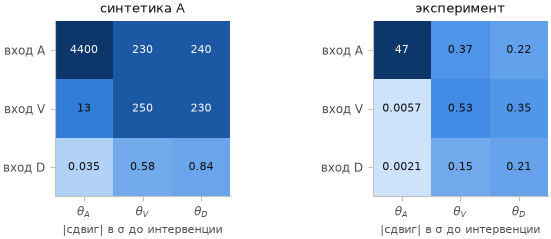

In [17]:
fig = show("cross")

Медианный |сдвиг| каждого параметра (столбец) в его σ, когда выносится вход одного элемента (строка), $k = 10$, $q = 5\,\%$.
Диагональ — собственный отклик. Вне диагонали — перенос: когда $\theta_A$ уменьшается, часть адвекции, общая с другими
входами (через условное среднее $\mu$), объясняется их параметрами. На синтетике это сотни σ (параметры очень точны),
на эксперименте — доли σ. Поэтому решение принимается по собственному отклику элемента, а удаление идёт по одному
элементу с переоценкой.

### 6.7. Вариант: интервенция на уровне сетки (листья дерева)

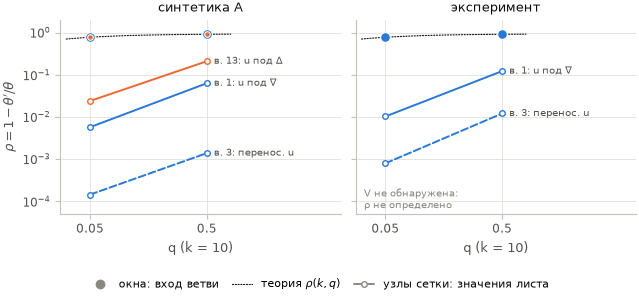

In [18]:
fig = show("leaf")

Вместо входа ветви в окне за $10\sigma$ выносятся значения листа $u$ в узлах сетки, $\sigma$ — условная по шести соседям.
Поля гладкие, и условная $\sigma$ мала: 0.050 маргинальной на эксперименте и 0.066 на синтетике,
так что вынос за $10\sigma$ — это всего 0.5–0.7 маргинальной σ. Слабая форма
усредняет такие точечные выбросы по окну, и параметр теряет в 4–5000 раз меньше, чем при выносе входа
окна. На эксперименте при $q = 5\,\%$ вынос значений $u$ в вершине 1 даёт $\mathrm{KL}_{сдв} = 0.19$ —
ниже порога, — а вынос входа окна при той же доле даёт 1.09e+03. Поэтому основная интервенция — на уровне окон,
где живёт переменная, из которой оценивается параметр.

### 6.8. Устойчивость к размеру пробных окон

| mx, mt | шаг x, t | строк | кластеров | R² | θ_A | θ_V | θ_D | оставлено |
|---|---|---|---|---|---|---|---|---|
| 5, 10 | 2, 10 | 66528 | 180 | 0.453 | 0.781 ± 0.012 | -6.4 ± 4.5 | 0.30 ± 0.85 | A |
| 6, 10 | 3, 10 | 14406 | 144 | 0.402 | 0.794 ± 0.013 | -4.4 ± 6.4 | -0.19 ± 0.90 | A |
| 8, 10 | 4, 10 | 5250 | 48 | 0.431 | 0.846 ± 0.021 | -2.9 ± 9.0 | -0.44 ± 0.83 | A |
| 6, 15 | 3, 15 | 8232 | 72 | 0.460 | 0.738 ± 0.018 | 6.4 ± 5.6 | -0.81 ± 0.89 | A |
| 6, 20 | 3, 20 | 6174 | 72 | 0.501 | 0.722 ± 0.019 | 2.7 ± 5.3 | 0.24 ± 0.73 | A |

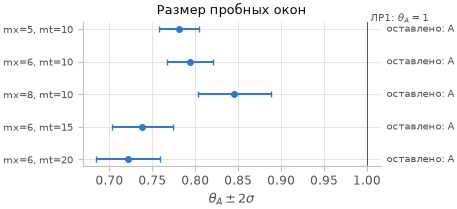

In [19]:
fig = show("scales")
display(Markdown(report.table_scales(REP["real"]["scales"])))
assert all(s["keep"] == {"A": True, "V": False, "D": False} for s in REP["real"]["scales"])

При пяти размерах окон решение одно и то же: остаётся только адвекция. $\theta_A$ меняется с масштабом (от 0.72 до 0.85):
коэффициент эффективный, он зависит от того, какие масштабы движения усредняет окно, — ещё одно указание на сглаживание
и шум входа, а не на ошибку структуры.

### 6.9. Обратное исключение

In [20]:
display(Markdown(report.table_elimination(REP["real"])))
steps = REP["real"]["steps"]
print(f"R²: полная модель ({' + '.join(steps[0]['model'])}) {steps[0]['r2']:.6f}, "
      f"итоговая ({' + '.join(steps[-1]['model'])}) {steps[-1]['r2']:.6f}, разница {steps[0]['r2'] - steps[-1]['r2']:.1e}")

| шаг | модель | R² | слабейший: KL сдвиг | удалён |
|---|---|---|---|---|
| 1 | A + V + D | 0.402064 | D: 0.0177 | D |
| 2 | A + V | 0.402058 | V: 0.392 | V |
| 3 | A | 0.401901 | A: 1.55e+03 | — |

R²: полная модель (A + V + D) 0.402064, итоговая (A) 0.401901, разница 1.6e-04


Сначала удаляется контроль ($\mathrm{KL}_{сдв} = 0.0177$), затем вязкость
(0.392 после переоценки), адвекция остаётся. $R^2$ без вязкости и контроля меньше на
1.6e-04 — эти элементы ничего не объясняют. После удаления $D$ наивный Фишер дал бы для $V$
сдвиг 1.84 — у самого порога; Годамбе — 0.392.

## 7. Решение на графе

Красное удаляется, зелёное добавляется. Слияние $\rho$ в $P = p/\rho$ удаляет вершины 8 ($\rho$) и 9 (деление) и добавляет
ребро 7→10; удаление вязкости — ветвь 12–15 и сумму 16; удаление контроля — ветвь 17–19 и сумму 20.

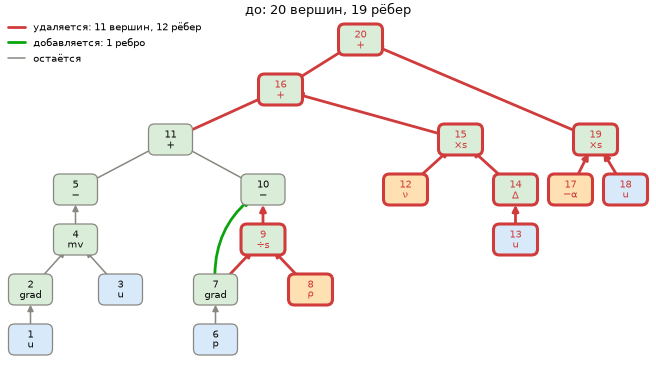

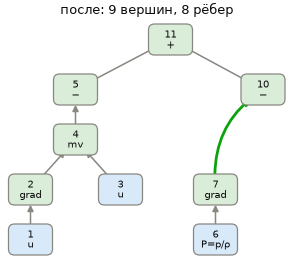

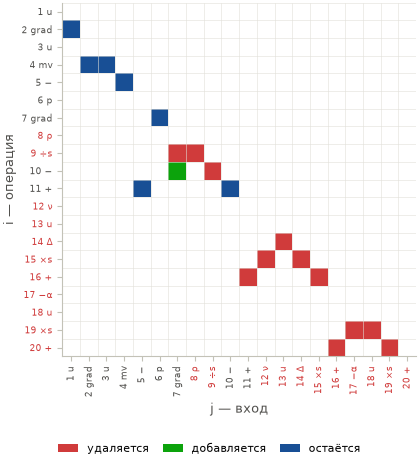

In [21]:
fig = show("decision_real")
fig = show("after_real")
fig = show("adjacency_real")

| данные | оставлено | до: вершин / рёбер | после | удалено вершин | удалено рёбер | добавлено рёбер |
|---|---|---|---|---|---|---|
| синтетика А: Навье–Стокс | A, V | 20 / 19 | 14 / 13 | 6 | 7 | 1 |
| синтетика Б: + трение α | A, V, D | 20 / 19 | 18 / 17 | 2 | 3 | 1 |
| эксперимент VIC#, случай 1L | A | 20 / 19 | 9 / 8 | 11 | 12 | 1 |

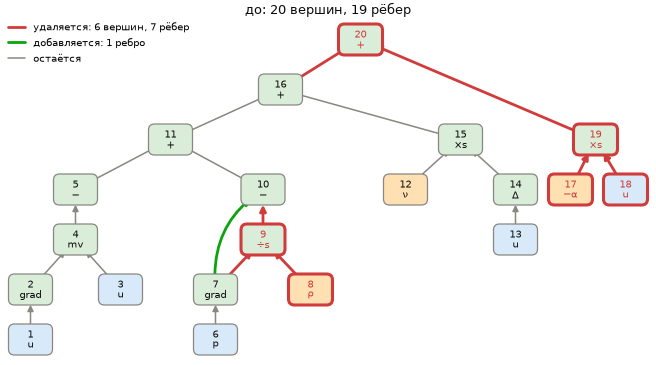

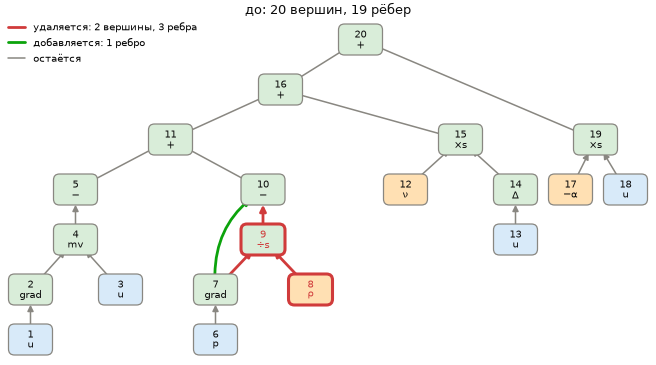

In [22]:
rows = []
for n in REP:
    d = graph.graph_diff(graph.candidate_tree(), graph.decided_tree(REP[n]["keep"]))
    kept = ", ".join(e for e in NAMES if REP[n]["keep"][e])
    rows.append([report.TITLE[n], kept, f"{d.before[0]} / {d.before[1]}", f"{d.after[0]} / {d.after[1]}",
                 len(d.removed_nodes), len(d.removed_edges), len(d.added_edges)])
display(Markdown(report.markdown_table(["данные", "оставлено", "до: вершин / рёбер", "после", "удалено вершин", "удалено рёбер",
                             "добавлено рёбер"], rows)))
for n in ("syn_a", "syn_b"):
    fig = show(f"decision_{n}")

Итоговые модели:

* эксперимент: $\partial_t u = -\theta_A (\nabla u) u - \nabla P$, $\nabla\cdot u = 0$ — **уравнение Эйлера** с кинематическим давлением
  (9 вершин, 8 рёбер);
* синтетика А: $\partial_t u = -(\nabla u)u - \nabla P + \nu\Delta u$ — Навье–Стокс (14/13);
* синтетика Б: то же $- \alpha u$ (18/17).

Вершины 8–9 удаляются на всех данных: это решение не статистическое, а структурное (раздел 2) — по полю скорости
$\rho$ отдельно от $p$ не определяется.

## 8. Выводы и ограничения

**Выводы.**

1. Критерий «$\mathrm{KL}_{сдв}$ после выноса входа элемента за $10\sigma$ условного распределения > 1.92 нат и допустимый
   знак» восстанавливает известную структуру на обеих синтетиках: удаляет отсутствующий контроль и сохраняет реальное
   трение $\alpha = 0.01$.
2. На эксперименте VIC# нужна только адвекция: вязкость при разрешении 1.6 мм не видна ($\theta_V = -4.4 ± 6.4$), контроль
   отсутствует; давление и $\rho$ структурно не идентифицируемы по скорости. Дерево ЛР №1 сводится к уравнению Эйлера.
3. Отклик на интервенцию количественно предсказуем: $\mathrm{KL}_{сдв} = \rho(k,q)^2 S_e$, где $S_e$ — KL до модели без элемента.
   Интервенция измеряет информацию о параметре, а $q^*$ — сколько окон нужно испортить, чтобы элемент «заметить».
4. Ширина распределения решает: наивная матрица Фишера занижает её в 2–4 раза и чаще оставляет лишнее; информация Годамбе
   верна для $V$, $D$ и всё ещё занижена для $A$ на синтетике.
5. В решении должен быть только сдвиг: форма KL растёт и у несуществующих элементов.

**Ограничения.**

* Распределение гауссово по построению (приближение Лапласа); бутстрэп подтверждает форму, но не проверяет хвосты дальше ~3σ.
* $\sigma_A$ на синтетике занижена вдвое и на эксперименте, вероятно, тоже: кластеры соседних окон не ловят корреляцию на
  масштабе всего блока. Для решений по $A$ это несущественно (запас $10^3$–$10^6$), для пограничных элементов было бы важно.
* $\theta_A < 1$ на эксперименте — эффективный коэффициент (шум и сглаживание входа); модель ошибок во входах
  (errors-in-variables) дала бы несмещённую оценку, но не меняет решения.
* Слабая форма с малыми окнами (половина ширины ≤ 5 ячеек) даёт ложное «оставить» для контроля из-за ошибки дискретизации
  (замечено в интеграционном тесте); основные окна — 6–8 ячеек, и решения устойчивы по пяти размерам окон.
* Порог 1.92 — уровень 5 % на один элемент без поправки на множественность (элементов три).

## 9. Воспроизводимость: живая проверка

Ячейки ниже не читают готовые числа, а пересчитывают их: (1) матрицы слабой формы заново из данных (DNS с теми же
зёрнами и файлы VIC#) и сравнивают с сохранёнными; (2) распределения из сохранённых матриц — с отчётом;
(3) решения на эксперименте — с отчётом; (4) запускают тесты.

In [23]:
for n in REP:
    data = config.data(n)
    design = Design.build(data, config.settings(n))
    stored = R.arrays[n]
    for key in ("y", "X", "clusters", "window", "component"):
        assert np.array_equal(getattr(design, key), stored[key]), (n, key)
    dists = estimation.distributions(design.X, design.y, design.names, design.clusters)
    for key, g in REP[n]["base"].items():
        loss, method = key.split("/")
        assert np.allclose(dists[loss, method].mean, g["mean"], rtol=1e-10, atol=0), (n, key)
        assert np.allclose(dists[loss, method].cov, g["cov"], rtol=1e-8, atol=0), (n, key)
    print(f"{n}: матрица {design.X.shape} совпадает с сохранённой, распределения совпадают с отчётом")
    if n == "real":
        tests = decision_tests(design, config.PLAN, config.DATASETS[n][0])
        for e in NAMES:
            assert tests[e]["keep"] == REP[n]["steps"][0]["tests"][e]["keep"]
            assert np.isclose(tests[e]["kl_shift"], REP[n]["steps"][0]["tests"][e]["kl_shift"], rtol=1e-9)
        print("real: решения и KL пересчитаны и совпадают с отчётом")

syn_a: матрица (31944, 3) совпадает с сохранённой, распределения совпадают с отчётом


syn_b: матрица (31944, 3) совпадает с сохранённой, распределения совпадают с отчётом


real: матрица (14406, 3) совпадает с сохранённой, распределения совпадают с отчётом
real: решения и KL пересчитаны и совпадают с отчётом


In [24]:
# Every figure of lab02/report.py is drawn by this run, so the slides find all of them, fresh, in figures/.
stale = [n for n in report.FIGURES
         if not (config.FIGURES / f"{n}.pdf").exists() or (config.FIGURES / f"{n}.pdf").stat().st_mtime < STARTED]
assert not stale, stale
run = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider"], cwd=ROOT,
                     capture_output=True, text=True)
print(run.stdout.strip().splitlines()[-1])
assert run.returncode == 0, run.stdout[-3000:]

79 passed in 8.35s


Порядок полного прогона: `python scripts/run_experiments.py` (≈ 2 мин, 8 процессов) → `python scripts/build_notebook.py` →
`python scripts/run_notebook.py` (этот ноутбук, сохраняет рисунки в `figures/`) → `python scripts/build_slides.py`.

## Источники

1. Hillestad, Eriksen, Bjerkeseth, Sætran, Bartl. Wake of a model wind turbine: volumetric velocity measurements (VIC#). *Phys. Rev. Fluids* 11, 014701 (2026); данные DataverseNO, doi:10.18710/SX0ZQT (CC0).
2. Эйнуллаев А. Навье–Стокс для следа ветротурбины, ЛР №1: github.com/Chessmatus/navie-stocks-aero, коммит 13e4e8f.
3. MacKay D. J. C. A practical Bayesian framework for backpropagation networks. *Neural Computation* 4(3), 448–472 (1992).
4. Кузнецов М. П., Токмакова А. А., Стрижов В. В. Анализ выбора моделей и оценка гиперпараметров // *Информатика и её применения* (2016).
5. Godambe V. P. An optimum property of regular maximum likelihood estimation. *Ann. Math. Statist.* 31, 1208–1211 (1960).
6. Liang K.-Y., Zeger S. L. Longitudinal data analysis using generalized linear models. *Biometrika* 73, 13–22 (1986).
7. Huber P. J. Robust estimation of a location parameter. *Ann. Math. Statist.* 35, 73–101 (1964).
8. Pukelsheim F. The three sigma rule. *The American Statistician* 48(2), 88–91 (1994).
9. Candès E., Fan Y., Janson L., Lv J. Panning for gold: model-X knockoffs for high-dimensional controlled variable selection. *JRSS B* 80, 551–577 (2018).
10. Rue H., Held L. *Gaussian Markov Random Fields: Theory and Applications*. Chapman & Hall/CRC (2005).
11. Frisch R., Waugh F. V. Partial time regressions as compared with individual trends. *Econometrica* 1, 387–401 (1933); Lovell M. C. *JASA* 58, 993–1010 (1963).
12. Kullback S., Leibler R. A. On information and sufficiency. *Ann. Math. Statist.* 22, 79–86 (1951).
13. Amari S. *Information Geometry and Its Applications*. Springer (2016).
14. Hassibi B., Stork D. G. Second order derivatives for network pruning: Optimal Brain Surgeon. *NIPS* 5 (1993).
15. Messenger D. A., Bortz D. M. Weak SINDy for partial differential equations. *J. Comput. Phys.* 443, 110525 (2021).
16. Efron B., Tibshirani R. J. *An Introduction to the Bootstrap*. Chapman & Hall (1993); Cameron A. C., Gelbach J. B., Miller D. L. Bootstrap-based improvements for inference with clustered errors. *REStat* 90, 414–427 (2008).